# Transformations: what information is preserved?

A transform changes coordinates or removes structure. This notebook follows generated data through scaling, dimensional reduction, whitening, differences, and factor models. The central questions are what is learned from the training rows, what can be reconstructed, and what remains in the residual.

We keep fitted maps and held-out observations separate. The figures and tables expose distortions in the original units as well as the transformed coordinates. [Transform contracts](../transforms.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import transforms as tx

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True,
                     "grid.alpha": .18, "figure.dpi": 110})

## Fit once; apply the same coordinates to new rows

Five observed coordinates are generated by two latent factors plus independent noise. Standardization estimates a location and scale from the training rows. Applying the fitted map to held-out rows reuses those values; it does not force the held-out means and variances to zero and one.

The table makes the fitting boundary visible. If the held-out distribution shifts, its standardized values should shift too.

In [2]:
B = np.array([[2.0, 0.0], [1.0, 0.2], [0.0, 2.0], [0.2, 1.5], [1.0, 1.0]])
psi = np.full(5, 0.35 ** 2)
latent = rng.normal(size=(2400, 2))
x = latent @ B.T + rng.normal(size=(2400, 5)) * np.sqrt(psi)
training, held_out = (x[:1800], x[1800:])
scaling = tx.standardize(training)
pd.DataFrame({'training location': scaling.location, 'training scale': scaling.scale})

,training location,training scale
0,-0.051009,2.023886
1,-0.025977,1.099810
2,-0.041590,2.031637
3,-0.016253,1.582321
4,-0.018012,1.500627


In [3]:
pd.DataFrame({"training mean after transform": scaling.transform(training).mean(axis=0),
              "held-out mean after transform": scaling.transform(held_out).mean(axis=0),
              "training SD after transform": scaling.transform(training).std(axis=0),
              "held-out SD after transform": scaling.transform(held_out).std(axis=0)},
             index=[f"coordinate {j}" for j in range(5)])

,training mean after transform,held-out mean after transform,training SD after transform,held-out SD after transform
coordinate 0,3.454027e-18,-0.003954,1.0,0.986096
coordinate 1,4.601258e-17,-0.010940,1.0,0.937485
coordinate 2,-1.120092e-16,0.026147,1.0,1.013002
coordinate 3,-3.441691e-17,0.004437,1.0,0.989050
coordinate 4,1.122559e-17,-0.019244,1.0,0.945413


## Outliers affect scaling before a model is fitted

Add one large value to an otherwise ordinary sample. Standard scaling uses the mean and standard deviation; robust scaling uses the median and an interquantile range. Min–max scaling is especially sensitive to the extreme endpoints.

Inspect the central 90% of the transformed observations as well as their location/scale parameters. A transform that compresses the central cloud may make later modelling harder even though it is perfectly invertible.

In [4]:
contaminated = np.r_[rng.normal(size=(100, 1)), [[40.0]]]
ordinary = tx.standardize(contaminated)
robust = tx.robust_scale(contaminated)
ranged = tx.minmax_scale(contaminated, lower=-1, upper=1)
pd.DataFrame({'standard': [ordinary.location[0], ordinary.scale[0]], 'robust': [robust.location[0], robust.scale[0]]}, index=['location', 'scale'])

,standard,robust
location,0.546792,0.285704
scale,4.071624,1.316794


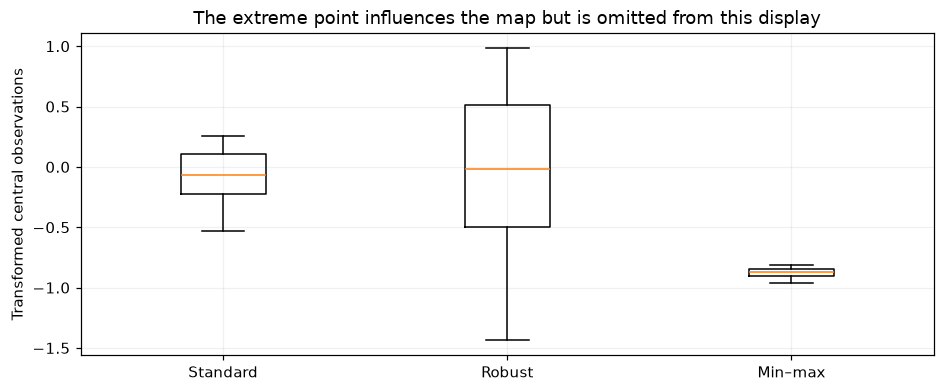

In [5]:
scaled_clouds = {"Standard": ordinary.transform(contaminated[:-1]).ravel(),
                 "Robust": robust.transform(contaminated[:-1]).ravel(),
                 "Min–max": ranged.transform(contaminated[:-1]).ravel()}
fig, ax = plt.subplots()
ax.boxplot(list(scaled_clouds.values()), tick_labels=list(scaled_clouds), whis=(5, 95), showfliers=False)
ax.set(ylabel="Transformed central observations", title="The extreme point influences the map but is omitted from this display")
plt.show()

## PCA explains variation, not necessarily the signal of interest

`pca` stores principal axes in **columns**. Retaining two axes gives scores and a reconstruction in the original five coordinates. The discarded directions appear in `residuals`; a reduced map has no exact inverse for arbitrary original inputs.

The scree plot suggests how many directions carry substantial variation. Compare held-out reconstruction error below across dimensions: additional components always retain more of these coordinates, including noise.

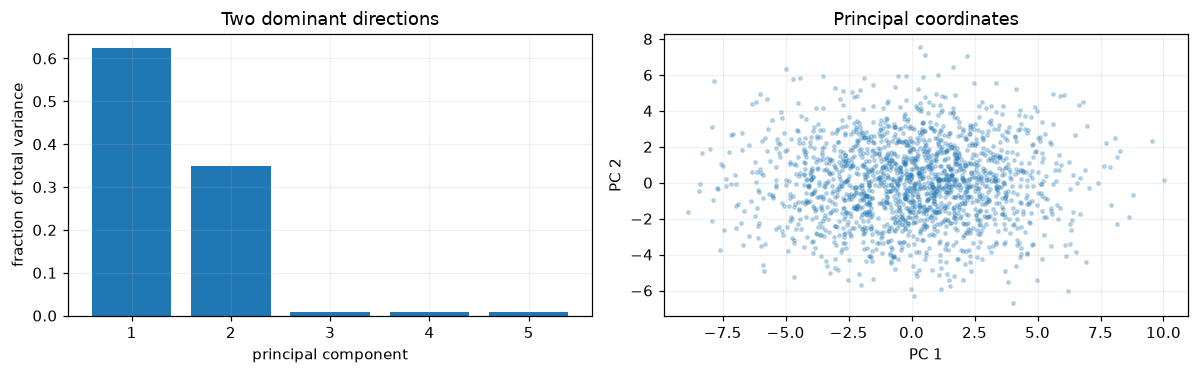

In [6]:
principal = tx.pca(training, n_components=2)
scores = principal.transform(training)
full = tx.pca(training)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(np.arange(1, 6), full.explained_variance_ratio)
axes[0].set(xlabel='principal component', ylabel='fraction of total variance', title='Two dominant directions')
axes[1].scatter(scores[:, 0], scores[:, 1], s=5, alpha=0.25)
axes[1].set(xlabel='PC 1', ylabel='PC 2', title='Principal coordinates')
plt.tight_layout()
plt.show()

In [7]:
reconstruction = []
for dimension in range(1, 6):
    fitted_pca = tx.pca(training, n_components=dimension)
    reconstruction.append({"components": dimension,
        "training RMSE": np.sqrt(np.mean(fitted_pca.residuals(training)**2)),
        "held-out RMSE": np.sqrt(np.mean(fitted_pca.residuals(held_out)**2))})
pd.DataFrame(reconstruction).set_index("components")

,training RMSE,held-out RMSE
components,,
1,1.031056e+00,1.059404e+00
2,2.745239e-01,2.665331e-01
3,2.205157e-01,2.195832e-01
4,1.539697e-01,1.508977e-01
5,6.352038e-16,5.898867e-16


## Standardizing before PCA changes the question

A pipeline fits each stage on the preceding stage's training output. PCA on raw coordinates favours large-variance coordinates. Standardizing first gives each coordinate equal initial variance, so it generally selects a different subspace.

Both reconstructions below are returned in the original observation units. Compare error coordinate by coordinate; one aggregate RMSE can hide which coordinates the map favours.

In [8]:
pipeline = tx.Pipeline((tx.Standardize(), tx.PCA(2))).fit(training)
pd.DataFrame({"raw-coordinate PCA RMSE": np.sqrt(np.mean(principal.residuals(held_out)**2, axis=0)),
              "scaled PCA RMSE": np.sqrt(np.mean(pipeline.residuals(held_out)**2, axis=0))},
             index=[f"coordinate {j}" for j in range(5)])

,raw-coordinate PCA RMSE,scaled PCA RMSE
coordinate 0,0.188050,0.342036
coordinate 1,0.306854,0.229827
coordinate 2,0.220883,0.285436
coordinate 3,0.295621,0.261626
coordinate 4,0.299158,0.292354


## Whitening changes the metric

PCA whitening rotates to principal coordinates and divides by their standard deviations. ZCA rotates back afterward. Both produce identity training covariance, but their coordinate geometry differs.

The plots use the same generated cloud. Inspect the orientation and scale of the resulting observations. Whitening requires positive variance in every retained direction; a singular direction must be omitted explicitly rather than rescued with an undocumented ridge.

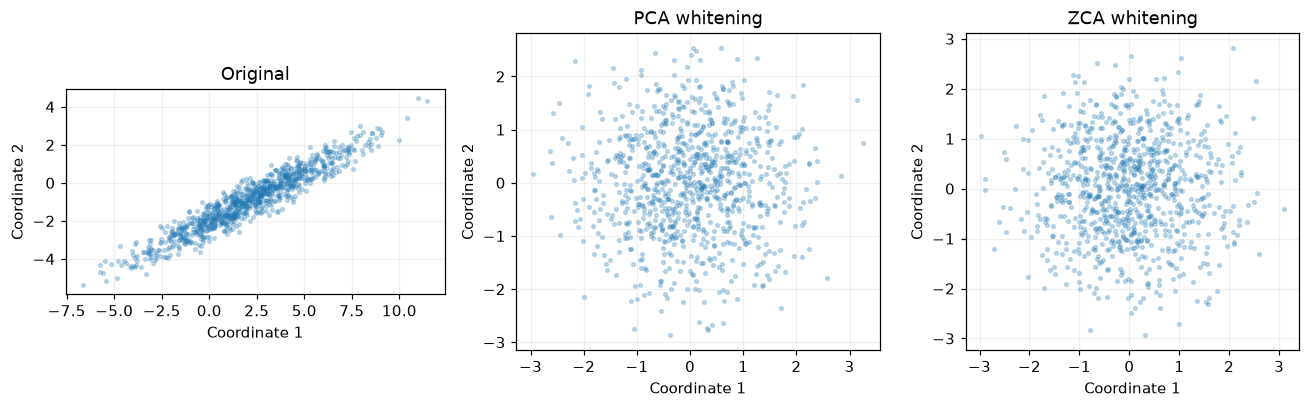

In [9]:
cloud = rng.normal(size=(900, 2)) @ np.array([[3., 1.5], [0., .5]]) + [2., -1.]
pca_white = tx.whitening(cloud, method="pca")
zca_white = tx.whitening(cloud, method="zca")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
for ax, values, label in zip(axes, [cloud, pca_white.transform(cloud), zca_white.transform(cloud)],
                           ["Original", "PCA whitening", "ZCA whitening"]):
    ax.scatter(values[:, 0], values[:, 1], s=6, alpha=.25)
    ax.set(title=label, xlabel="Coordinate 1", ylabel="Coordinate 2", aspect="equal")
plt.show()

## Differencing removes levels; inversion needs boundary values

For a seasonal lag $s$, $D_s x_t=x_t-x_{t-s}$. Repeated differencing removes additional structure. The omitted leading rows carry boundary information, so `DifferenceResult` retains the values needed to reconstruct the original series or integrate a continuation.

Here future differences come from the **known generated curve**. Reintegrating them demonstrates alignment and boundary handling; it does not forecast those differences. The continuation joins the history without a level jump. For the quadratic trend $0.01t^2$, the second lag-12 difference is the constant $2(0.01)(12^2)=2.88$; the period-12 sine term disappears.

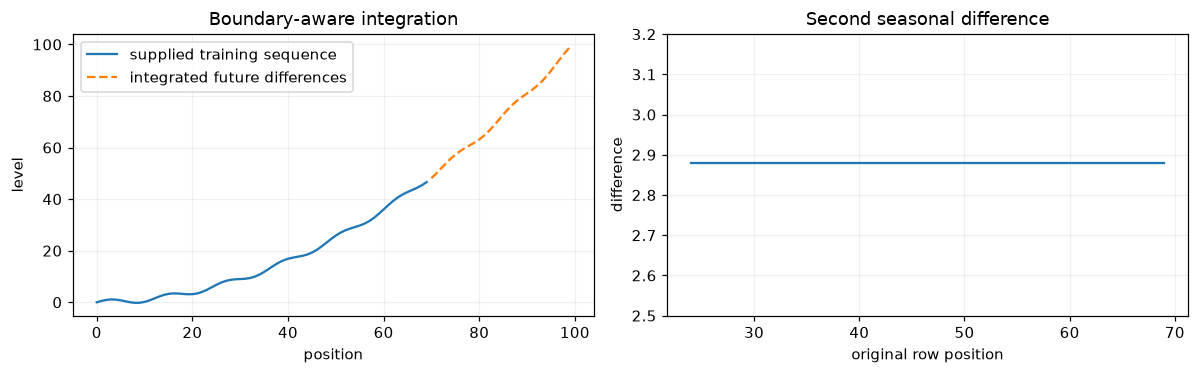

In [10]:
t = np.arange(100.0)
y = 0.01 * t ** 2 + np.sin(2 * np.pi * t / 12)
training_y = y[:70]
delta = tx.difference(training_y, lag=12, order=2)
whole_delta = tx.difference(y, lag=12, order=2)
future_delta = whole_delta.values[70 - delta.row_offset:]
restored_future = delta.inverse_transform(future_delta, continuation=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(t[:70], training_y, label='supplied training sequence')
axes[0].plot(t[70:], restored_future, '--', label='integrated future differences')
axes[0].set(xlabel='position', ylabel='level', title='Boundary-aware integration')
axes[0].legend()
axes[1].plot(delta.rows, delta.values)
axes[1].set(xlabel='original row position', ylabel='difference', title='Second seasonal difference', ylim=(2.5, 3.2))
plt.tight_layout()
plt.show()

## Lags and Fourier features have explicit row meaning

Lag zero uses the current row; positive lags refer to earlier rows. For predictive use, choose lags that are available at the decision time. The table exposes which original row each feature belongs to.

Fourier features are deterministic sine/cosine pairs. Using `start` preserves phase across a split. Resetting it for a continuation would silently change the feature values at the forecast boundary.

In [11]:
lagged = tx.lag_features(y, lags=(0, 1, 12))
pd.DataFrame(lagged.values[:6], index=lagged.rows[:6], columns=lagged.columns)

,x0_lag0,x0_lag1,x0_lag12
12,1.440000,0.710000,0.000000
13,2.190000,1.440000,0.510000
14,2.826025,2.190000,0.906025
15,3.250000,2.826025,1.090000
16,3.426025,3.250000,1.026025
17,3.390000,3.426025,0.750000


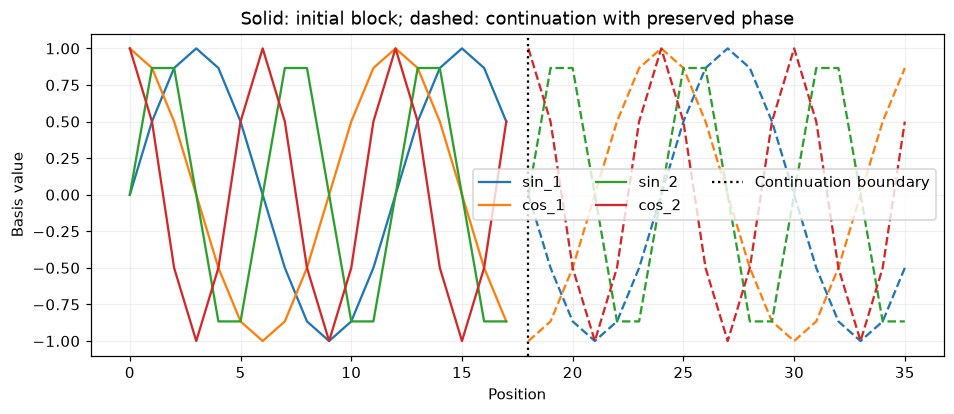

In [12]:
terms = tx.FourierFeatures(period=12, order=3)
first, continuation = terms(18), terms(18, start=18)
fig, ax = plt.subplots()
for j in range(4):
    line, = ax.plot(first.rows, first.values[:, j], label=first.columns[j])
    ax.plot(continuation.rows, continuation.values[:, j], "--", color=line.get_color())
ax.axvline(18, color="black", linestyle=":", label="Continuation boundary")
ax.set(xlabel="Position", ylabel="Basis value", title="Solid: initial block; dashed: continuation with preserved phase")
ax.legend(ncol=3)
plt.show()

## A Gaussian factor model shrinks latent scores

In $x=\mu+Bf+\epsilon$, latent factors have unit covariance and observation-specific noise has diagonal covariance $\Psi$. The model covariance is $BB^T+\Psi$. `GaussianFactorModel.transform` computes posterior factor means, which shrink noisy directions; they are not an orthogonal projection like PCA scores.

The fitted loading columns are rotationally ambiguous. Compare implied covariance, noise variance, and principal subspace angles with the generating model instead of demanding elementwise equality of loadings.

In [13]:
known = tx.GaussianFactorModel(np.zeros(5), B, psi)
factors = tx.factor_analysis(training, n_components=2, rotation='varimax')
factor_scores = factors.transform(held_out)
pd.DataFrame({'generating noise variance': psi, 'fitted noise variance': factors.noise_variance})

,generating noise variance,fitted noise variance
0,0.1225,0.086958
1,0.1225,0.136151
2,0.1225,0.124381
3,0.1225,0.124287
4,0.1225,0.131520


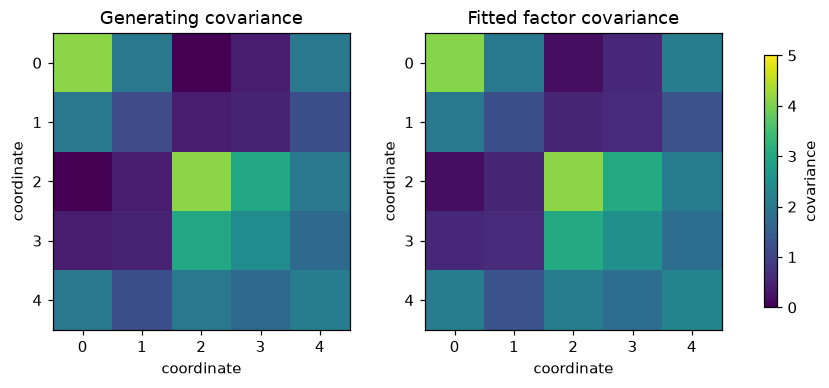

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, covariance, title in zip(axes, [known.covariance, factors.covariance], ['Generating covariance', 'Fitted factor covariance']):
    im = ax.imshow(covariance, cmap='viridis', vmin=0, vmax=5)
    ax.set(title=title, xlabel='coordinate', ylabel='coordinate')
    ax.grid(False)
fig.colorbar(im, ax=axes, label='covariance', shrink=0.85)
plt.show()

In [15]:
angles = np.degrees(tx.principal_angles(tx.subspace(B), tx.subspace(factors.loadings)))
display(pd.DataFrame({"principal angle (degrees)": angles}, index=["direction 1", "direction 2"]))
pd.DataFrame({"generating noise variance": psi, "estimated noise variance": factors.noise_variance},
             index=[f"coordinate {j}" for j in range(5)])

,principal angle (degrees)
direction 1,0.405517
direction 2,0.201605


,generating noise variance,estimated noise variance
coordinate 0,0.1225,0.086958
coordinate 1,0.1225,0.136151
coordinate 2,0.1225,0.124381
coordinate 3,0.1225,0.124287
coordinate 4,0.1225,0.131520


Try increasing the noise in one coordinate or changing the scale of one loading. Revisit raw PCA, scaled PCA, and factor analysis: they need not react in the same way because they preserve different geometry and make different noise assumptions. [Subspace and custom-map interfaces](../transforms.md) extend these examples without changing the fitted-map contract.